# Token swaps in J-space — Qwen3.5-9B

**Question.** Does exchanging two token-vector coordinates at intermediate layers change the model's final answer to the answer implied by the replacement concept?

**Answer (this run: `Qwen/Qwen3.5-9B` at `c202236`, bfloat16, prefitted lens `bcywinski/jacobian-lens-qwen3.5-9b/lens_n1000.pt`).** Yes, often, and far more than the controls. In the predeclared primary setting (α=1, middle band, blocks 13–18), the J-space swap makes the replacement concept's answer the top-1 token for:

| dataset | J swap | logit-direction swap | random (norm-matched) | prompts with a correct baseline |
|---|---|---|---|---|
| latent-bridge (country → language) | **67.7%** | 1.5% | 0.0% | 83 |
| probe-swap | **41.0%** | 2.6% | 0.0% | 39 |
| flexible-generalization | **35.6%** | 0.0% | 0.0% | 29 |

The random arm almost never changes the output (≤ 0.4%), so the J effect is not just disruption. The logit-direction swap without J does almost nothing in the early and middle bands. In the late band (blocks 19–25) it starts to work too (latent-bridge 34.4% at α=1, 79.2% at α=2), so the J lens adds the most at earlier depths. Exploratory settings are stronger, e.g. α=2 in the middle band: latent-bridge 95.2%, probe-swap 69.2%, flexible-generalization 64.9%. They are not held-out results.

Baseline accuracy (per prompt) is 91.2% on latent-bridge, 60.9% on probe-swap and 64.4% on flexible-generalization. Flips are conditional on a correct baseline. On flexible-generalization the effect depends on the task: country capital/language prompts flip 100%/92% (4 prompts each), but number and month tasks rarely do (doubling 8%, successor 0%, next month 0%, season 25%; 4 prompts each). These per-task counts are small.

**Data decision.** Use Anthropic's original `probe-swap` and `flexible-generalization` datasets, plus this repository's `latent-bridge` v1, after the explicit quality exclusions below. Do **not** use GPT-2-filtered latent-bridge v2 as a neutral cross-model benchmark. Keep all three datasets separate.

This is a next-token causal experiment, not a free-generation evaluation. A changed token alone is not a successful conceptual swap.

## Repository setup (local or Colab)

In a fresh Colab session, clone this GitHub fork; reuse an existing clone with
`git pull --ff-only` and install its dependencies into the active Python environment.
A notebook opened inside a local checkout uses that checkout directly. Clone, pull,
and installation errors stop the setup cell. Run this cell before importing `jlens`;
if you already imported an older version in this session, restart the runtime first.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/ai360-project-school-j-lens/jacobian-lens-gpt2.git"
IN_COLAB = "COLAB_RELEASE_TAG" in os.environ or "google.colab" in sys.modules

# Reuse a checkout when opened locally, including from a nested notebook folder.
local_repo = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "jlens" / "evaluation.py").is_file()),
    None,
)
REPO_DIR = local_repo or Path.cwd() / "jacobian-lens-gpt2"
if local_repo is not None:
    if IN_COLAB:
        subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=True)
elif REPO_DIR.exists():
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=True)
else:
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)

ROOT = REPO_DIR.resolve()
if IN_COLAB:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-e", str(ROOT)], check=True,
    )
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
if not (ROOT / "jlens" / "swap_experiment.py").is_file():
    raise RuntimeError("Update this checkout to the revision containing jlens/swap_experiment.py.")
print(f"Repository ready: {ROOT.name}")

Repository ready: jacobian-lens-gpt2


In [2]:
import json

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display

from jlens.swap_experiment import (
    experiment_fingerprint,
    intermediate_bands,
    load_swap_trials,
    prepare_swap_trials,
    run_swap_experiment,
)

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_columns", 20)
RUN_MODEL = os.environ.get("JLENS_RUN_MODEL", "1") == "1"  # Set True for pretrained inference.
MODEL_ID = os.environ.get("JLENS_MODEL_ID", "Qwen/Qwen3.5-9B")
MODEL_REVISION = os.environ.get(
    "JLENS_MODEL_REVISION", "c202236235762e1c871ad0ccb60c8ee5ba337b9a",
)  # Pinned Hub commit of the evaluated snapshot.
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.bfloat16  # transformers loads Qwen3.5-9B in bf16 even when float32 is requested
EXISTING_LENS_PATH = os.environ.get("JLENS_LENS_PATH")  # Matching FINAL lens; never a checkpoint.
# Published J-lens files checked at the pinned Neuronpedia revision below.
HUB_LENS_FILES = {
    "Qwen/Qwen3-4B": "qwen3-4b/jlens/Salesforce-wikitext/Qwen3-4B_jacobian_lens.pt",
    "Qwen/Qwen3-1.7B": "qwen3-1.7b/jlens/Salesforce-wikitext/Qwen3-1.7B_jacobian_lens.pt",
    "openai-community/gpt2": "gpt2-small/jlens/Salesforce-wikitext/gpt2_jacobian_lens.pt",
    "google/gemma-4-31B": "gemma-4-31b/jlens/Salesforce-wikitext/gemma-4-31B_jacobian_lens.pt",
    "Qwen/Qwen3.5-9B-Base": "qwen3.5-9b-pt/jlens/Salesforce-wikitext/Qwen3.5-9B-Base_jacobian_lens.pt",
    "Qwen/Qwen3.5-4B": "qwen3.5-4b/jlens/Salesforce-wikitext/Qwen3.5-4B_jacobian_lens_n1000.pt",
}
HUB_LENS = (
    dict(repo_id="neuronpedia/jacobian-lens", filename=HUB_LENS_FILES[MODEL_ID],
         revision="9fa267f841d62aa468dab5b9b38c3dc45a82d863")
    if MODEL_ID in HUB_LENS_FILES and not EXISTING_LENS_PATH else None
)
# For another model, supply its exact artifact: dict(repo_id=..., filename=..., revision=...).
if MODEL_ID == "Qwen/Qwen3.5-9B" and not EXISTING_LENS_PATH:
    HUB_LENS = dict(repo_id="bcywinski/jacobian-lens-qwen3.5-9b", filename="lens_n1000.pt",
                    revision="3711de15301882c0629970f687192804966840a3")
FIT_LENS = False  # Set True and HUB_LENS=None only to deliberately run/load a managed fit.
LENS_PROVENANCE = None
lens = None
BATCH_SIZE = 16
ALPHAS = [0.0, 1.0, 2.0]
SEED = 0
MAX_PROMPT_LENGTH = 256
RUN_ROOT = ROOT / "runs/model-agnostic-token-swap"
results = prepared = None
print(f"Pretrained experiment enabled: {RUN_MODEL}; device: {DEVICE}")

Pretrained experiment enabled: True; device: cuda


## Dataset provenance and quality

The local `probe-swap.json` and `flexible-generalization.json` were verified **byte-for-byte** against [Anthropic's upstream release at commit 581d398](https://github.com/anthropics/jacobian-lens/tree/581d398613e5602a5af361e1c34d3a92ea82ba8e/data/experiments). Their hashes and the review decisions are in `data/experiments/token-swap-audit.json`; the original data are unchanged. The [paper](https://transformer-circuits.pub/2026/workspace/index.html) motivates bandwise coordinate interventions; this notebook is an adaptation, not an exact replication of its model or scores.

The review found incomplete answer labels (e.g. `North`, `Canadian`, `Civil`, and square answers `twenty`/`forty`/`eighty`), underspecified relations, and counterfactuals that violate the question's answer type. The China population premise is outdated: see [UN DESA's 2023 population brief](https://www.un.org/development/desa/pd/content/policy-brief153). Exclusions are conservative review decisions, not an exhaustive certification that every retained fact and alternative wording is correct.

Local v1 has 400 trials from **100 landmark prompts**, each with four replacement countries. It is useful as a narrow supplementary country→language task, with repeated prompts and simplified language labels. Remove ambiguous transboundary/disputed landmarks and India language trials conservatively. V2 has 1,416 trials from 354 subjects selected on GPT-2 XL answers; its 100% construction baseline does not transfer to other models. The default uses v1 instead. Explicit-source flexible tasks and latent-source two-hop tasks must not be pooled.

In [3]:
audit = json.loads((ROOT / "data/experiments/token-swap-audit.json").read_text())
trials = load_swap_trials(ROOT)
quality_summary = trials.groupby("dataset").agg(
    raw_trials=("name", "size"), raw_prompts=("prompt", "nunique"),
    retained_trials=("quality_ok", "sum"),
)
quality_summary["retained_prompts"] = trials[trials.quality_ok].groupby("dataset").prompt.nunique()
display(quality_summary)
display(trials[~trials.quality_ok].groupby(["dataset", "quality_reason"]).size().rename("excluded_trials").to_frame())
print(audit["latent_v2"])
for limitation in audit["limitations"]:
    print("•", limitation)

,raw_trials,raw_prompts,retained_trials,retained_prompts
dataset,,,,
flexible-generalization,192,64,144,48
latent-bridge,400,100,344,91
probe-swap,90,86,71,68


excluded_trials
dataset                 quality_reason                                                                                                       
flexible-generalization Biggest holiday is culture-dependent, Easter moves, and labels are fragments.                                      12
                        North is an incomplete answer for North America; exclude the whole relation for balanced coverage.                 12
                        Sky/outdoors do not specify a unique natural habitat.                                                              12
                        twenty, forty and eighty are only prefixes of 25, 49 and 81.                                                       12
latent-bridge           Country attribution in East Jerusalem is disputed.                                                                  8
                        One canonical main-language label hides substantial linguistic diversity; excluded conservatively.                 40
                        Transboundary landmark does not identify a unique country.                                                          4
                        Transboundary landmark does not identify a unique country.; One canonical main-language label hid...                4
probe-swap              At least one label is only a prefix of a multi-word answer.                                                         7
                        Belgium has more than one western neighbor; direction is underspecified.                                            1
                        Colors depend on species; the eagle label is underspecified.                                                        1
                        Easter does not have a fixed month.                                                                                 1
                        Lung lobes are not heart chambers; the counterfactual changes relation.                                             1
                        Outdated China premise; India overtook China in 2023.                                                               1
                        Seasons require a hemisphere; none is specified.                                                                    1
                        The counterfactual asks for a fruit, but barley is a cereal.                                                        1
                        The counterfactual asks for an animal but labels earth.                                                             1
                        The counterfactual asks for an insect but labels a cow.                                                             1
                        The counterfactual rider's power source is ill-formed for a train.                                                  1
                        The swan-to-England national-emblem relation is not well defined.                                                   1
                        Wooden objects used to strike an instrument do not describe piano keys.                                             1

Excluded from default experiments: 1416 rows are four targets for 354 subjects preselected for GPT-2 XL capability. Use v1 for cross-model coverage; v2 requires a separately reported model-specific analysis.
• Latent bridge v1 has one country-to-language relation, 100 source landmarks and four targets per prompt, not 400 independent questions.
• Country/language labels simplify multilingual countries; retained labels are canonical continuations, not exhaustive accepted answers.
• Single-token scoring undercounts valid synonyms, number forms and multi-token answers; report coverage for each tokenizer.
• Anthropic flexible tasks explicitly mention the source; report separately from hidden intermediate tasks.
• Do not select the best band on the same prompts and call its score held-out performance.


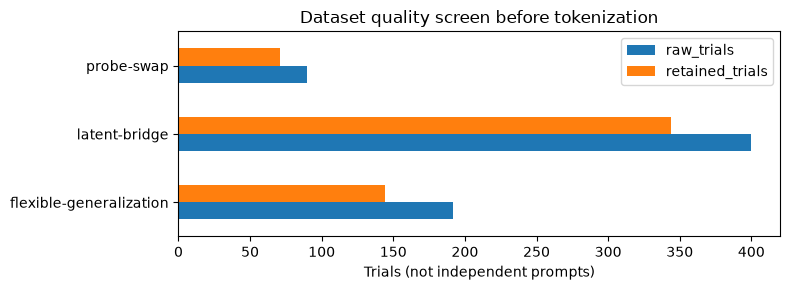

In [4]:
fig, ax = plt.subplots(figsize=(8, 3))
quality_summary[["raw_trials", "retained_trials"]].plot.barh(ax=ax)
ax.set(xlabel="Trials (not independent prompts)", ylabel="", title="Dataset quality screen before tokenization")
plt.tight_layout()
plt.show()

## Intervention and scoring

For source and replacement token directions at layer ℓ, form `V = [v_source, v_target]`. Compute clean coordinates `c_clean = V⁺ h_clean`. After each selected block, set

`h_patched ← h_patched + V[c_clean + α(swap(c_clean) − c_clean) − V⁺h_patched]`.

At α=1, the two clean coordinates exchange; the orthogonal component is preserved. Clamping to clean coordinates avoids undoing the swap on alternate layers. `α=0` is an exact no-op. The J directions are `Jᵀ C(gain × unembedding)` for LayerNorm and `Jᵀ(gain × unembedding)` for RMSNorm. Effective norm gain includes offset parameterizations such as Gemma's `1 + weight`.

Three arms run over the same prompts: J-space swap; logit-direction swap without J; and a random update matched **at each layer and position to the actual J arm's update norm**. The random seed is fixed; random draws depend on batching, which is recorded. α=2 and the band sweep are exploratory. The predeclared primary setting is **α=1, middle of the three depth bands**. Do not report the best observed setting as held-out performance.

Prompts use the adapter's normal special-token policy, without a chat wrapper or silent truncation. A concept must have a complete, exact single-token spelling (space-prefixed first, otherwise bare). Answers use complete single-token case/space variants only; no first-token fallback. Both answer sets must be nonempty and disjoint. Multi-token words are excluded and counted, not silently replaced by their first token.

Prompts are length-grouped and batched; compatible adapters use right padding and attention masks. Other adapters use equal-length batches. All real non-special prompt positions are patched. BOS, EOS and padding are untouched. The final distribution is obtained from the last block at each row's last real token through `model.unembed`, including the model's final normalization and logit transforms.

Report baseline accuracy over eligible data, then target flips conditional on a unique correct baseline top token. Also show any-output-change rate and target-probability gain. Tied top scores are not accepted as capability or success. Ranks use competition ranks and are descriptive. Multiple targets for one prompt are correlated: summary rates first average within each prompt, then across prompts. There are no trial-independent confidence intervals.

## Executed CPU smoke check

This random, untrained decoder only checks the intervention mechanics. Its output changes do **not** demonstrate factual concept transfer. Regression tests additionally check distinct per-row coordinates, padding, exact no-ops, random norm matching, token rejection, normalization, and hook cleanup.

In [5]:
from jlens import JacobianLens
from tests.tiny import TinyDecoder

smoke_model = TinyDecoder().eval()
smoke_lens = JacobianLens(
    {layer: torch.eye(smoke_model.d_model) for layer in range(smoke_model.n_layers)},
    n_prompts=1, d_model=smoke_model.d_model,
)
smoke_trials = pd.DataFrame([
    dict(trial_id=str(i), dataset="synthetic", group="smoke", name=str(i),
         prompt=str(i), source="a", target="b", answer="c", swap_answer="d",
         input_ids=ids, source_id=source, target_id=target,
         answer_ids=[4, 5], swap_answer_ids=[6, 7], eligible=True)
    for i, (ids, source, target) in enumerate([
        ([0, 1, 2, 3], 3, 9), ([0, 2, 3], 4, 10), ([0, 5, 6, 7], 5, 11),
    ])
])
smoke = run_swap_experiment(
    smoke_model, smoke_lens, smoke_trials, bands={"middle": [1, 2]},
    alphas=[0.0, 1.0], batch_size=3, seed=SEED, progress=False,
)
assert not smoke[smoke.alpha.eq(0)].changed.any()
display(smoke.groupby(["mode", "alpha"]).agg(trials=("name", "size"), changed=("changed", "sum")))
print("CPU smoke passed: all zero-strength arms preserve the final top token.")

trials  changed
mode   alpha                 
J      0.0         3        0
       1.0         3        2
logit  0.0         3        0
       1.0         3        2
random 0.0         3        0
       1.0         3        1

CPU smoke passed: all zero-strength arms preserve the final top token.


## Load a model and a matching lens

Enable `RUN_MODEL` in the configuration cell. Change `MODEL_ID` and optionally `MODEL_REVISION`; the same evaluator handles any supported `from_hf` layout. Models must be in evaluation mode. This notebook uses one device and fp32 by default; large models need sufficient memory or an explicitly chosen supported dtype. No architecture-specific layer path is used here.

**Default: download the pretrained J-lens from [neuronpedia/jacobian-lens](https://huggingface.co/neuronpedia/jacobian-lens/tree/9fa267f841d62aa468dab5b9b38c3dc45a82d863).** `MODEL_ID` defaults to Qwen3-4B, matching the original pretrained swap notebook. `HUB_LENS` selects its exact file and pins a Hub commit; the preset table also covers several other models. For another published model, supply `HUB_LENS = dict(repo_id=..., filename=..., revision=...)` explicitly. The old Qwen3-0.6B default has no J-lens file in this pinned repository snapshot.

`download_lens_artifact(**HUB_LENS)` downloads the selected file or reuses the Hub cache, checks its published SHA-256 and size, and passes that exact path to the existing lens loader. Width and layer coverage are checked against the selected model. The receipt is displayed and saved with the results; artifact verification does not establish the legacy lens's fitting provenance. A missing/failed Hub download stops and never triggers fitting.

Alternatively, set `HUB_LENS=None` and `EXISTING_LENS_PATH` to a matching local final lens. To deliberately load or create a managed fit, set both sources to `None` and `FIT_LENS=True`. The managed fit records model/runtime, dtype, corpus mix, sequence length, dimension batch size, and exact ordered texts, with resumable checkpoints. No swap prompts are used to fit J. The displayed fitting configuration applies only to this managed-fit option, not to downloaded artifacts.

Run caches live under ignored `runs/`. The result key covers runtime, resolved model revision, tokenizer vocabulary, exact tokenized trials, bands, strengths, batching, seed, implementation, and actual lens matrices. A completed result file skips all expensive clean/patched passes on rerun; interrupted result sweeps restart, while fitting supports checkpoint resume. Local modified model weights need a new explicit run label.

In [6]:
lens = None  # A failed load must not leave an earlier lens available.
results = prepared = None
LENS_PROVENANCE = None
if RUN_MODEL:
    if sum([HUB_LENS is not None, bool(EXISTING_LENS_PATH), FIT_LENS]) != 1:
        raise ValueError("Choose one lens source: HUB_LENS, EXISTING_LENS_PATH, or FIT_LENS=True.")
    import hashlib

    import transformers
    from transformers import AutoModelForCausalLM, AutoTokenizer

    import jlens
    from jlens.artifact_provenance import download_lens_artifact
    from jlens.evaluation import FIT_MIX, fit_with_progress, load_fit_prompts
    from jlens.notebook_setup import DatasetFitRun, runtime_metadata
    from jlens.sharded_fitting import benchmark_dim_batches

    torch.manual_seed(SEED)
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
    hf_model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID, revision=MODEL_REVISION, dtype=DTYPE,
    ).to(DEVICE).eval()
    model = jlens.from_hf(hf_model, tokenizer, compile=False)
    RUNTIME = runtime_metadata(model, hf_model, MODEL_ID, DTYPE, DEVICE)
    FIT_CONFIG = {
        **RUNTIME,
        "max_seq_len": 128, "skip_first": 16,
        "fit_mix": {key: max(1, round(count * 0.25)) for key, count in FIT_MIX.items()},
        "seed": SEED, "run_label": "token-swap-v1", "checkpoint_every": 5,
        "dim_batch_requested": 8, "candidates": [4, 8, 16, 32],
        "headroom_fraction": 0.15, "headroom_GiB": 2.0,
    }
    fit_run = DatasetFitRun(RUN_ROOT / "fits", FIT_CONFIG)
    selected_path = EXISTING_LENS_PATH
    if HUB_LENS is not None:
        artifact = download_lens_artifact(**HUB_LENS)
        selected_path = artifact.path
        LENS_PROVENANCE = {**artifact.to_dict(), "evaluation_runtime": RUNTIME}
        display(LENS_PROVENANCE)
    lens = fit_run.load_or_fit(
        model, FIT_CONFIG, load_prompts=load_fit_prompts,
        fit=fit_with_progress, benchmark=benchmark_dim_batches,
        display=display, existing_path=selected_path,
    )
    LENS_PATH = str(selected_path or fit_run.lens_path)
    LENS_SOURCE = "hub" if HUB_LENS is not None else "local" if selected_path else "managed"
    BANDS = intermediate_bands(model.n_layers)
    PRIMARY_BAND = list(BANDS)[len(BANDS) // 2]
    prepared = prepare_swap_trials(model, trials, max_length=MAX_PROMPT_LENGTH)
    display(prepared.groupby("dataset").agg(
        raw=("name", "size"), quality_ok=("quality_ok", "sum"),
        token_ok=("token_ok", "sum"), eligible=("eligible", "sum"),
    ))
    display(prepared[~prepared.token_ok].groupby(["dataset", "token_reason"]).size().rename("trials").to_frame())
    print("Primary band:", PRIMARY_BAND, "; all bands:", BANDS)
else:
    print("Pretrained model/lens loading skipped. Enable RUN_MODEL to measure causal success.")

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

{'repo_id': 'bcywinski/jacobian-lens-qwen3.5-9b',
 'filename': 'lens_n1000.pt',
 'requested_revision': '3711de15301882c0629970f687192804966840a3',
 'resolved_revision': '3711de15301882c0629970f687192804966840a3',
 'sha256': '25f7c003432b44f01b94a45a32322a4994186aad9110060a463392806a6525ba',
 'size': 1040196725,
 'path': '/workspace/.hf_home/hub/models--bcywinski--jacobian-lens-qwen3.5-9b/snapshots/3711de15301882c0629970f687192804966840a3/lens_n1000.pt',
 'verification': 'Hub LFS size and SHA-256 at resolved revision',
 'fitting_provenance': 'unverified legacy final lens',
 'evaluation_runtime': {'model_id': 'Qwen/Qwen3.5-9B',
  'dtype': 'bfloat16',
  'device': 'cuda:0',
  'mode': 'single',
  'd_model': 4096,
  'n_layers': 32,
  'model_class': 'Qwen3_5ForCausalLM',
  'training': False,
  'attention_implementation': 'sdpa',
  'model_revision': None,
  'tokenizer_class': 'Qwen2Tokenizer',
  'tokenizer_name': 'Qwen/Qwen3.5-9B',
  'tokenizer_revision': None,
  'tokenizer_special_ids': [2480

UNVERIFIED legacy lens: /workspace/.hf_home/hub/models--bcywinski--jacobian-lens-qwen3.5-9b/snapshots/3711de15301882c0629970f687192804966840a3/lens_n1000.pt; skipping downloads, benchmark, and fit.


,raw,quality_ok,token_ok,eligible
dataset,,,,
flexible-generalization,192,144,170,128
latent-bridge,400,344,400,344
probe-swap,90,71,81,67


trials
dataset                 token_reason                                        
flexible-generalization answer has no complete single-token spelling      22
probe-swap              answer has no complete single-token spelling       7
                        multi-token or invalid concept                     2

Primary band: 13:19 ; all bands: {'6:13': [6, 7, 8, 9, 10, 11, 12], '13:19': [13, 14, 15, 16, 17, 18], '19:26': [19, 20, 21, 22, 23, 24, 25]}


In [7]:
if RUN_MODEL:
    if lens is None:
        raise RuntimeError("Load the selected lens successfully before running swaps.")
    metadata = {
        **(FIT_CONFIG if LENS_SOURCE == "managed" else RUNTIME),
        "model_revision_requested": MODEL_REVISION,
        "model_revision_resolved": getattr(hf_model.config, "_commit_hash", None),
        "tokenizer_sha256": hashlib.sha256(json.dumps(tokenizer.get_vocab(), sort_keys=True).encode()).hexdigest(),
        "torch_version": torch.__version__, "transformers_version": transformers.__version__,
        "bands": BANDS, "alphas": ALPHAS, "batch_size": BATCH_SIZE,
        "max_prompt_length": MAX_PROMPT_LENGTH, "seed": SEED,
        "lens_n_prompts": lens.n_prompts,
        "lens_origin": LENS_PATH, "lens_source": LENS_SOURCE,
        "lens_artifact": LENS_PROVENANCE,
        "fit_provenance": "managed independent corpus" if LENS_SOURCE == "managed" else "unverified existing artifact",
    }
    key = experiment_fingerprint(metadata, prepared, lens)
    run_dir = RUN_ROOT / key
    run_dir.mkdir(parents=True, exist_ok=True)
    if LENS_PROVENANCE is not None:
        (run_dir / "downloaded_lens_provenance.json").write_text(json.dumps(LENS_PROVENANCE, indent=2))
    result_path = run_dir / "results.json"
    prepared.to_json(run_dir / "trial_audit.json", orient="records", indent=2)
    (run_dir / "manifest.json").write_text(json.dumps(metadata, indent=2))
    if result_path.exists():
        results = pd.DataFrame(json.loads(result_path.read_text()))
        print("Loaded cached model passes:", result_path)
    else:
        results = run_swap_experiment(
            model, lens, prepared, bands=BANDS, alphas=ALPHAS,
            batch_size=BATCH_SIZE, seed=SEED,
        )
        temporary = result_path.with_suffix(".tmp.json")
        results.to_json(temporary, orient="records", indent=2, double_precision=15)
        temporary.replace(result_path)
    print("Completed result rows:", len(results))
else:
    print("No pretrained results have been computed or loaded.")

swap batches:   0%|          | 0/34 [00:00<?, ?it/s]

Completed result rows: 14553


## Results: coverage, capability, and causal effects

Baseline accuracy is recomputed independently for the selected model. Excluding incorrect baselines is a capability condition, not evidence that the entire raw dataset is solvable. Compare coverage and baseline accuracy before comparing models' conditional swap rates. Retain the per-trial audit and report the intersection of eligible prompts for stricter cross-model comparisons.

In [8]:
summary = primary = None
if results is not None and not results.empty:
    baseline = results.drop_duplicates("trial_id")
    display(baseline.groupby("dataset").agg(
        eligible_trials=("name", "size"), eligible_prompts=("prompt", "nunique"),
        baseline_correct_trials=("base_correct", "sum"),
    ))
    display(baseline.drop_duplicates(["dataset", "prompt"]).groupby("dataset").base_correct.agg(["mean", "size"]))
    correct = results[results.base_correct].copy()
    correct["probability_gain"] = correct.probability - correct.base_probability
    keys = ["dataset", "mode", "band", "alpha"]
    if not correct.empty:
        per_prompt = correct.groupby(keys + ["prompt"])[["success", "changed", "probability_gain"]].mean()
        summary = per_prompt.groupby(keys).agg(
            target_flip=("success", "mean"), any_change=("changed", "mean"),
            probability_gain=("probability_gain", "mean"), prompts=("success", "size"),
        ).reset_index()
        primary = summary[summary.band.eq(PRIMARY_BAND) & summary.alpha.eq(1)]
        display(primary)
        display(summary)
        display(correct[correct['mode'].eq("J") & correct.band.eq(PRIMARY_BAND) & correct.alpha.eq(1)].groupby("dataset").head(8)[
            ["dataset", "prompt", "source", "target", "baseline_text", "patched_text", "swap_answer", "success"]
        ])
    else:
        print("No eligible prompt has a unique correct baseline answer; causal success is undefined.")
else:
    print("No pretrained results available; no success rates to report.")

,eligible_trials,eligible_prompts,baseline_correct_trials
dataset,,,
flexible-generalization,128,45,82
latent-bridge,344,91,313
probe-swap,67,64,40


,mean,size
dataset,,
flexible-generalization,0.644444,45
latent-bridge,0.912088,91
probe-swap,0.609375,64


,dataset,mode,band,alpha,target_flip,any_change,probability_gain,prompts
1,flexible-generalization,J,13:19,1.0,0.356322,0.431034,0.184590,29
10,flexible-generalization,logit,13:19,1.0,0.000000,0.000000,0.001192,29
19,flexible-generalization,random,13:19,1.0,0.000000,0.000000,0.000100,29
28,latent-bridge,J,13:19,1.0,0.676707,0.817269,0.279498,83
37,latent-bridge,logit,13:19,1.0,0.015060,0.035141,0.007674,83
46,latent-bridge,random,13:19,1.0,0.000000,0.004016,0.000067,83
55,probe-swap,J,13:19,1.0,0.410256,0.538462,0.230883,39
64,probe-swap,logit,13:19,1.0,0.025641,0.076923,0.004994,39
73,probe-swap,random,13:19,1.0,0.000000,0.000000,0.000411,39


,dataset,mode,band,alpha,target_flip,any_change,probability_gain,prompts
0,flexible-generalization,J,13:19,0.0,0.000000,0.000000,0.000000,29
1,flexible-generalization,J,13:19,1.0,0.356322,0.431034,0.184590,29
2,flexible-generalization,J,13:19,2.0,0.649425,0.793103,0.299023,29
3,flexible-generalization,J,19:26,0.0,0.000000,0.000000,0.000000,29
4,flexible-generalization,J,19:26,1.0,0.321839,0.448276,0.164952,29
...,...,...,...,...,...,...,...,...
76,probe-swap,random,19:26,1.0,0.000000,0.000000,0.000007,39
77,probe-swap,random,19:26,2.0,0.000000,0.000000,0.000285,39
78,probe-swap,random,6:13,0.0,0.000000,0.000000,0.000000,39
79,probe-swap,random,6:13,1.0,0.000000,0.000000,-0.000162,39


,dataset,prompt,source,target,baseline_text,patched_text,swap_answer,success
192,flexible-generalization,Two times three equals,three,five,six,six,ten,False
193,flexible-generalization,Two times three equals,three,seven,six,six,fourteen,False
194,flexible-generalization,Two times three equals,three,nine,six,six,eighteen,False
195,flexible-generalization,Two times five equals,five,three,ten,ten,six,False
196,flexible-generalization,Two times five equals,five,seven,ten,ten,fourteen,False
197,flexible-generalization,Two times five equals,five,nine,ten,ten,eighteen,False
198,flexible-generalization,Two times seven equals,seven,three,fourteen,fourteen,six,False
199,flexible-generalization,Two times seven equals,seven,five,fourteen,,ten,False
2365,latent-bridge,The Kremlin is in a country where the main language is,Russia,Portugal,Russian,Portuguese,Portuguese,True
2366,latent-bridge,The Kremlin is in a country where the main language is,Russia,Japan,Russian,Japanese,Japanese,True


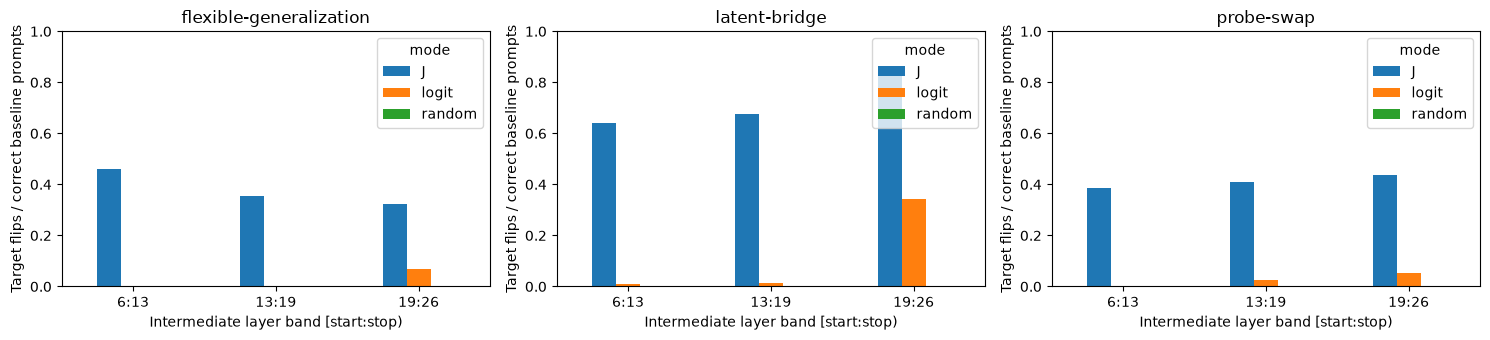

In [9]:
if summary is not None and not summary.empty:
    selected = summary[summary.alpha.eq(1)]
    datasets = list(selected.dataset.unique())
    fig, axes = plt.subplots(1, len(datasets), figsize=(5 * len(datasets), 3.5), squeeze=False)
    for ax, dataset in zip(axes[0], datasets, strict=True):
        table = selected[selected.dataset.eq(dataset)].pivot(index="band", columns="mode", values="target_flip")
        table.reindex(list(BANDS)).plot.bar(ax=ax, ylim=(0, 1), rot=0)
        ax.set(title=dataset, ylabel="Target flips / correct baseline prompts", xlabel="Intermediate layer band [start:stop)")
    plt.tight_layout()
    plt.show()

## Conclusions

The original Anthropic datasets are already present and authentic, but authenticity does not make every label suitable for strict whole-answer scoring. The audited versions and local latent-bridge v1 are useful complementary diagnostics. V1 measures only country→language transfer; v2's GPT-2 XL preselection makes it unsuitable as the default cross-model dataset.

A J-space intervention supports specific conceptual transfer when the correct target answer becomes top-1 more often than under random perturbations, with the baseline originally correct. A large any-change rate alone can reflect disruption. Logit-direction controls show whether J adds value. Use the primary setting for the headline and the full band/strength grid for exploration. Single-token coverage, alternate valid answers, correlated targets, and limited relation diversity remain limitations.

In [10]:
if primary is None or primary.empty:
    print("Current empirical conclusion: data audit and CPU mechanics only. Pretrained causal effects remain unmeasured.")
else:
    for dataset in primary.dataset.unique():
        frame = primary[primary.dataset.eq(dataset)].set_index("mode")
        print(f"{dataset}, primary band {PRIMARY_BAND}, α=1: " + "; ".join(
            f"{mode} target flips {row.target_flip:.1%}, any change {row.any_change:.1%}, n={int(row.prompts)} prompts"
            for mode, row in frame.iterrows()
        ))

flexible-generalization, primary band 13:19, α=1: J target flips 35.6%, any change 43.1%, n=29 prompts; logit target flips 0.0%, any change 0.0%, n=29 prompts; random target flips 0.0%, any change 0.0%, n=29 prompts
latent-bridge, primary band 13:19, α=1: J target flips 67.7%, any change 81.7%, n=83 prompts; logit target flips 1.5%, any change 3.5%, n=83 prompts; random target flips 0.0%, any change 0.4%, n=83 prompts
probe-swap, primary band 13:19, α=1: J target flips 41.0%, any change 53.8%, n=39 prompts; logit target flips 2.6%, any change 7.7%, n=39 prompts; random target flips 0.0%, any change 0.0%, n=39 prompts
